The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


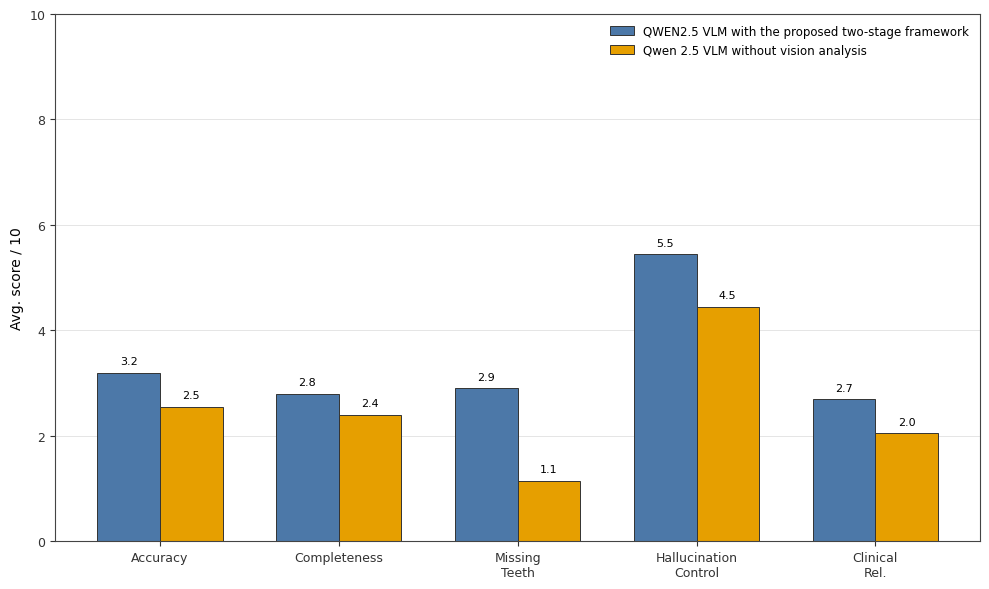

Saved → average_per_metric_barchart.eps


In [1]:
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt

METRICS = ['Accuracy', 'Completeness', 'Missing Teeth Detection', 'Hallucination Control', 'Clinical Relevance']
SHORT = ['Accuracy', 'Completeness', 'Missing\nTeeth', 'Hallucination\nControl', 'Clinical\nRel.']
COLORS = {'ours': '#378ADD', 'non': '#D85A30'}


def parse_csvs(filepaths, label):
    rows = []
    for fp in filepaths:
        df = pd.read_csv(fp)
        for _, row in df.iterrows():
            annotator = row["Nom d'utilisateur"]
            images = {}
            for col in df.columns:
                m = re.match(r"(train_\d+\.png) - Critères d'évaluation \[(.+)\]", col)
                if m:
                    img, metric = m.group(1), m.group(2)
                    images.setdefault(img, {"annotator": annotator, "image_id": img})
                    images[img][metric] = pd.to_numeric(row[col], errors='coerce')
            rows.extend(images.values())
    df_out = pd.DataFrame(rows)[["annotator", "image_id"] + METRICS]
    df_out["image_id"] = df_out["image_id"].str.replace(".png", "", regex=False)
    df_out["_n"] = df_out["image_id"].str.extract(r"(\d+)").astype(int)
    df_out = df_out.sort_values("_n").drop(columns="_n").reset_index(drop=True)
    df_out["overall"] = df_out[METRICS].mean(axis=1).round(2)
    df_out["group"] = label
    return df_out


# Load the two sets (with and without vision analysis)
a1 = parse_csvs(['expert_evaluation_part_1.csv', 'expert_evaluation_part_2.csv'], 'ours')
a2 = parse_csvs(['expert_without_json_part_1.csv', 'expert_without_json_part_2.csv'], 'non')

# Compute per-metric averages
vals1 = [a1[m].mean() for m in METRICS]
vals2 = [a2[m].mean() for m in METRICS]

xi = np.arange(len(METRICS))
w = 0.35
# =========================================================
# FIGURE — SCIENTIFIC PAPER STYLE
# =========================================================

xi = np.arange(len(METRICS))
w = 0.35

fig, ax = plt.subplots(
    figsize=(10, 6),
    facecolor="white"
)

# White plotting background
ax.set_facecolor("white")

# Bars
ax.bar(
    xi - w/2,
    vals1,
    w,
    color="#4C78A8",
    edgecolor="#333333",
    linewidth=0.7,
    label="QWEN2.5 VLM with the proposed two-stage framework"
)

ax.bar(
    xi + w/2,
    vals2,
    w,
    color="#E69F00",
    edgecolor="#333333",
    linewidth=0.7,
    label="Qwen 2.5 VLM without vision analysis"
)

# X axis
ax.set_xticks(xi)
ax.set_xticklabels(
    SHORT,
    fontsize=9
)

# Y axis
ax.set_ylim(0, 10)
ax.set_ylabel(
    "Avg. score / 10",
    fontsize=10
)

# Light scientific-paper grid
ax.grid(
    axis="y",
    color="#D9D9D9",
    linewidth=0.6,
    alpha=0.8
)

ax.set_axisbelow(True)

# Visible border around figure
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("#444444")
    spine.set_linewidth(0.8)

# Tick style
ax.tick_params(
    axis="both",
    colors="#333333",
    labelsize=9
)

# Values above bars
for i, (v1, v2) in enumerate(zip(vals1, vals2)):

    ax.text(
        i - w/2,
        v1 + 0.12,
        f"{v1:.1f}",
        ha="center",
        va="bottom",
        fontsize=8,
        color="black"
    )

    ax.text(
        i + w/2,
        v2 + 0.12,
        f"{v2:.1f}",
        ha="center",
        va="bottom",
        fontsize=8,
        color="black"
    )

# Legend
ax.legend(
    fontsize=8.5,
    frameon=False,
    loc="upper right"
)

# NO TITLE
# The title/description should be in the LaTeX caption.

# Layout
fig.tight_layout()

# =========================================================
# SAVE AS EPS
# =========================================================

fig.savefig(
    "average_per_metric_barchart.eps",
    format="eps",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

plt.close(fig)

print(
    "Saved → average_per_metric_barchart.eps"
)